# Эксперименты для плана дежурств

Для каждого метода выполняются 20 независимых запусков с `seed=1000,…,1019`. Бюджет каждого запуска — ровно 6000 вычислений фитнеса, включая начальную популяцию. Сравниваются итоговые мягкие цели только допустимых решений; отдельно приводится доля допустимых результатов.

Используются однофакторные сравнения: `GA_penalty_reassign` отличается от базового `GA_repair_reassign` только обработкой ограничений, а `GA_repair_bit_flip` — только типом мутации. `Random_feasible` использует ремонтированные случайные решения без эволюции при том же бюджете.

In [1]:
%matplotlib inline
import json
from collections.abc import Callable
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd

from duty_ga import (
    GAConfig, GeneticAlgorithm, constructive_schedule, generate_problem,
    random_feasible_search, save_instance, schedule_table, solution_metrics,
)

RESULTS_DIR = Path('results')
PLOTS_DIR = Path('plots')
CONFIGS_DIR = Path('configs')
for directory in (RESULTS_DIR, PLOTS_DIR, CONFIGS_DIR):
    directory.mkdir(exist_ok=True)

N_RUNS = 20
BASE_SEED = 1000
problem = generate_problem()
save_instance(problem, CONFIGS_DIR / 'problem_instance.json')
base_config = GAConfig(seed=BASE_SEED)
configs = {
    'GA_repair_reassign': base_config,
    'GA_penalty_reassign': replace(base_config, constraint_handler='penalty'),
    'GA_repair_bit_flip': replace(base_config, mutation='bit_flip'),
}

## Вспомогательные функции

`run_series` создаёт независимые конфигурации с разными seed. В CSV сохраняются фитнес с учётом возможного штрафа, отдельно мягкая цель, допустимость, число нарушений, нагрузки, фактический бюджет и время. Для сводной статистики используются мягкие цели только допустимых решений.

In [2]:
def save_json(data: dict, path: Path) -> None:
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


def run_series(run_once: Callable, config: GAConfig) -> list[dict]:
    results = []
    for run in range(N_RUNS):
        cfg = replace(config, seed=BASE_SEED + run)
        result = run_once(problem, cfg)
        assert result['n_evals'] == cfg.budget
        result.update(run=run, seed=cfg.seed, config=asdict(cfg))
        results.append(result)
    return results


def series_to_dataframe(results: list[dict]) -> pd.DataFrame:
    columns = (
        'run', 'seed', 'best_fitness', 'best_objective', 'feasible',
        'hard_violations', 'preference', 'imbalance', 'loads', 'n_evals',
        'elapsed_seconds',
    )
    return pd.DataFrame([{key: result[key] for key in columns} for result in results])


def summarize(df: pd.DataFrame) -> dict:
    quality = df.loc[df['feasible'], 'best_objective']
    return {
        'best': float(quality.min()),
        'mean': float(quality.mean()),
        'median': float(quality.median()),
        'std': float(quality.std(ddof=1)),
        'worst': float(quality.max()),
        'feasible_rate': float(df['feasible'].mean()),
        'mean_evals': float(df['n_evals'].mean()),
        'mean_seconds': float(df['elapsed_seconds'].mean()),
    }


def plot_convergence(results: list[dict], name: str) -> None:
    histories = np.asarray([result['best_history'] for result in results])
    evaluations = np.asarray(results[0]['eval_history'])
    mean = histories.mean(axis=0)
    std = histories.std(axis=0, ddof=1)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(evaluations, mean, label='Среднее', color='navy')
    ax.fill_between(evaluations, mean - std, mean + std, alpha=0.2, color='navy', label='±1 стандартное отклонение')
    ax.plot(evaluations, histories.min(axis=0), label='Минимум', color='green', linestyle='--')
    ax.plot(evaluations, histories.max(axis=0), label='Максимум', color='red', linestyle='--')
    ax.set(xlabel='Число вычислений фитнеса', ylabel='Лучший фитнес', title=f'Сходимость: {name}')
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f'convergence_{name}.png', dpi=150)
    plt.show()
    plt.close(fig)

## Запуск серий

Следующая ячейка перезаписывает результаты и конфигурации. Сравнение методов выполняется на одном экземпляре и при равном числе оцениваний; время приведено как дополнительная характеристика, а не как нормированный бюджет.

In [3]:
save_json(asdict(base_config), CONFIGS_DIR / 'base.json')
for name, cfg in configs.items():
    save_json(asdict(cfg), CONFIGS_DIR / f'{name}.json')

all_results = {}
for name, cfg in configs.items():
    print(f'Выполняется {name}...')
    all_results[name] = run_series(lambda p, c: GeneticAlgorithm(p, c).run(), cfg)
print('Выполняется Random_feasible...')
all_results['Random_feasible'] = run_series(random_feasible_search, base_config)

assert all(r['feasible'] for r in all_results['GA_repair_reassign'])
assert all(r['feasible'] for r in all_results['GA_repair_bit_flip'])
assert all(r['feasible'] for r in all_results['Random_feasible'])

Выполняется GA_repair_reassign...


Выполняется GA_penalty_reassign...


Выполняется GA_repair_bit_flip...


Выполняется Random_feasible...


## Статистика серий

Best, mean, median, std и worst относятся к мягкой цели $f$: меньше означает лучше. `feasible_rate` показывает долю запусков, вернувших решение без жёстких нарушений. Стандартное отклонение выборочное ($ddof=1$).

In [4]:
all_summaries = {}
for name, results in all_results.items():
    df = series_to_dataframe(results)
    df.to_csv(RESULTS_DIR / f'{name}.csv', index=False)
    all_summaries[name] = summarize(df)

summary_df = pd.DataFrame(all_summaries).T
summary_df.index.name = 'method'
summary_df.to_csv(RESULTS_DIR / 'summary.csv')
save_json(all_results, RESULTS_DIR / 'all_results.json')
save_json(all_summaries, RESULTS_DIR / 'summary.json')
display(summary_df.round(3))

print('Запуски базовой конфигурации:')
display(series_to_dataframe(all_results['GA_repair_reassign']).round(3))

,best,mean,median,std,worst,feasible_rate,mean_evals,mean_seconds
method,,,,,,,,
GA_repair_reassign,7.0,7.00,7.0,0.000,7.0,1.0,6000.0,1.441
GA_penalty_reassign,15.0,19.60,19.0,3.119,28.0,1.0,6000.0,0.225
GA_repair_bit_flip,7.0,7.00,7.0,0.000,7.0,1.0,6000.0,1.439
Random_feasible,7.0,7.35,7.0,0.489,8.0,1.0,6000.0,1.436


Запуски базовой конфигурации:


,run,seed,best_fitness,best_objective,feasible,hard_violations,preference,imbalance,loads,n_evals,elapsed_seconds
0,0,1000,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.407
1,1,1001,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.429
2,2,1002,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.409
3,3,1003,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.431
4,4,1004,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.466
5,5,1005,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.428
6,6,1006,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.439
7,7,1007,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.429
8,8,1008,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.446
9,9,1009,7.0,7.0,True,0,7,0.0,"[3, 3, 3, 3, 3, 3, 3]",6000,1.448


## Графики сходимости и сравнение качества

На графиках сходимости показаны средняя траектория, диапазон ±1 стандартное отклонение, минимум и максимум по 20 запускам. У штрафного метода ось фитнеса включает штрафы, поэтому её начальный масштаб несопоставим с мягкой целью остальных методов. Итоговое сравнение ниже использует только $f$ допустимых решений.

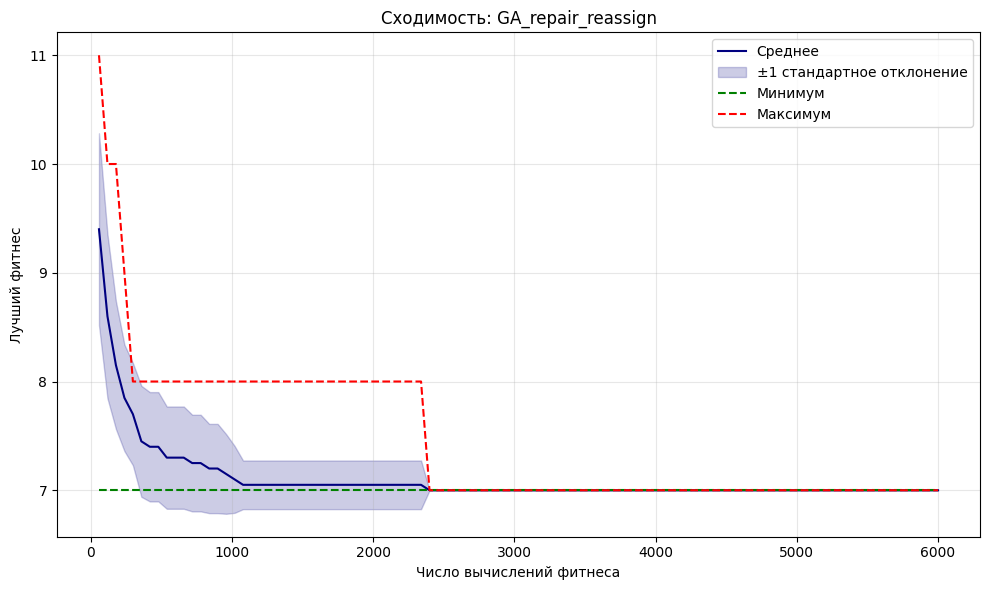

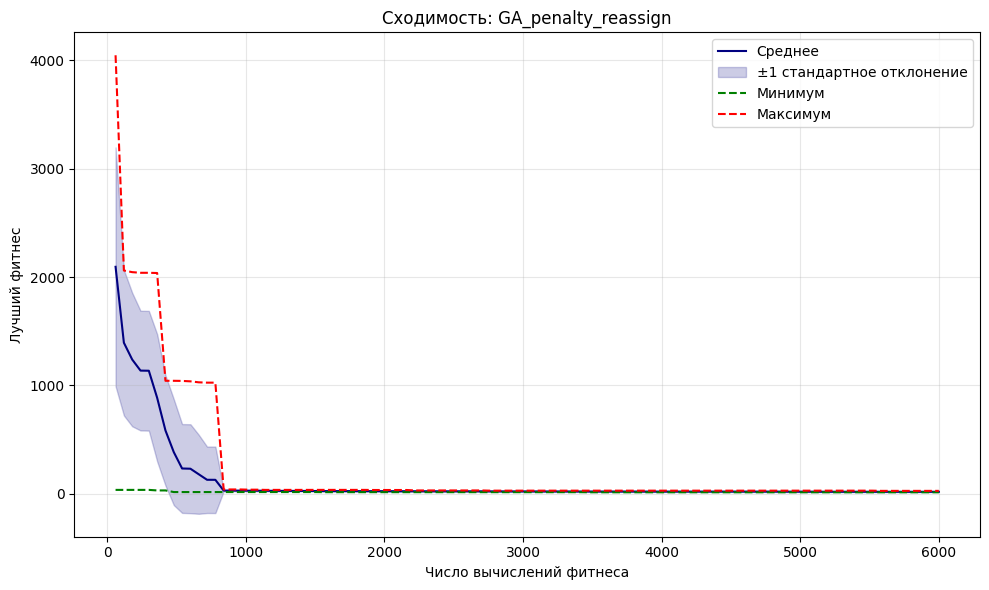

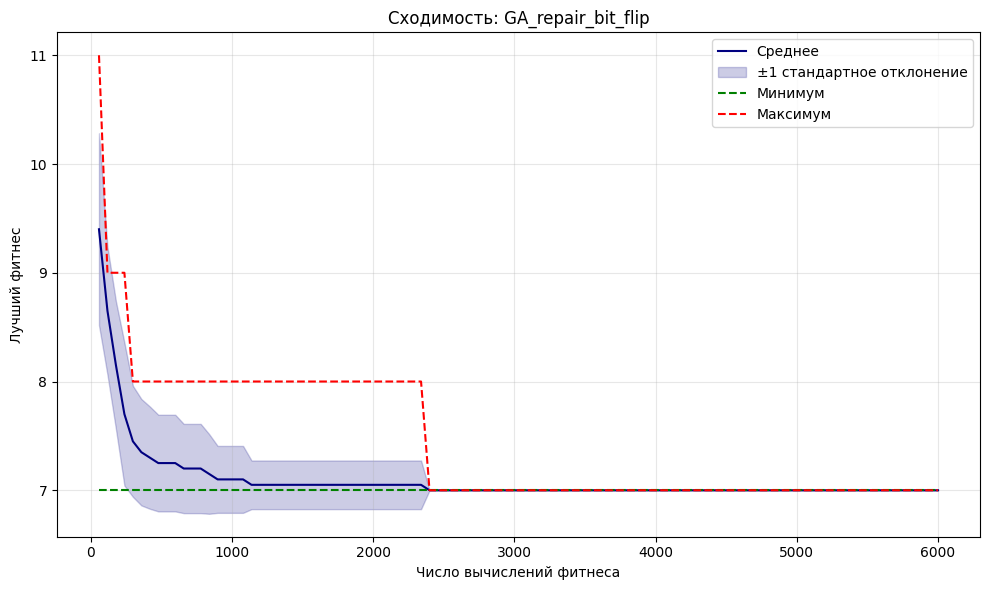

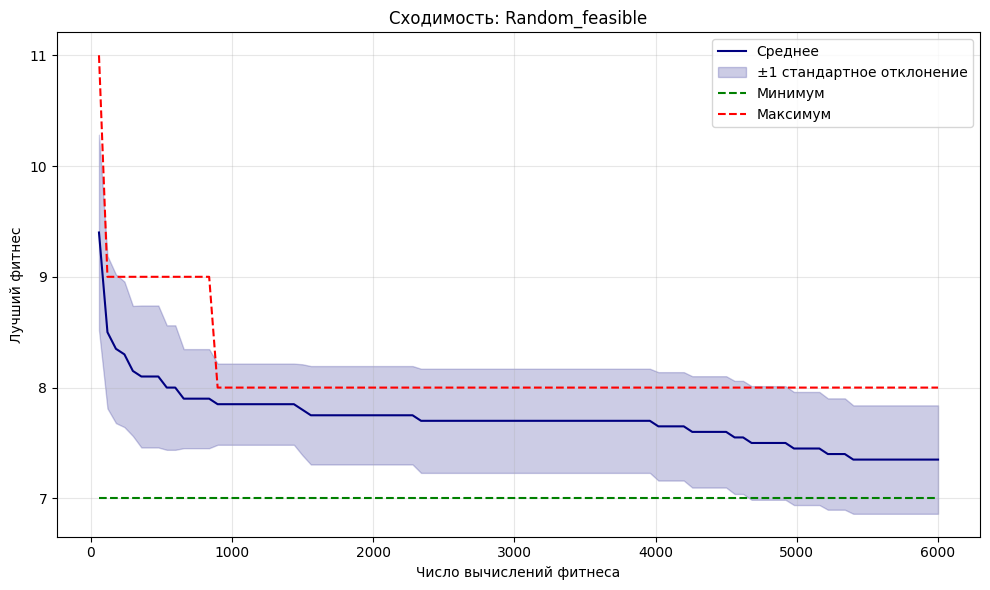

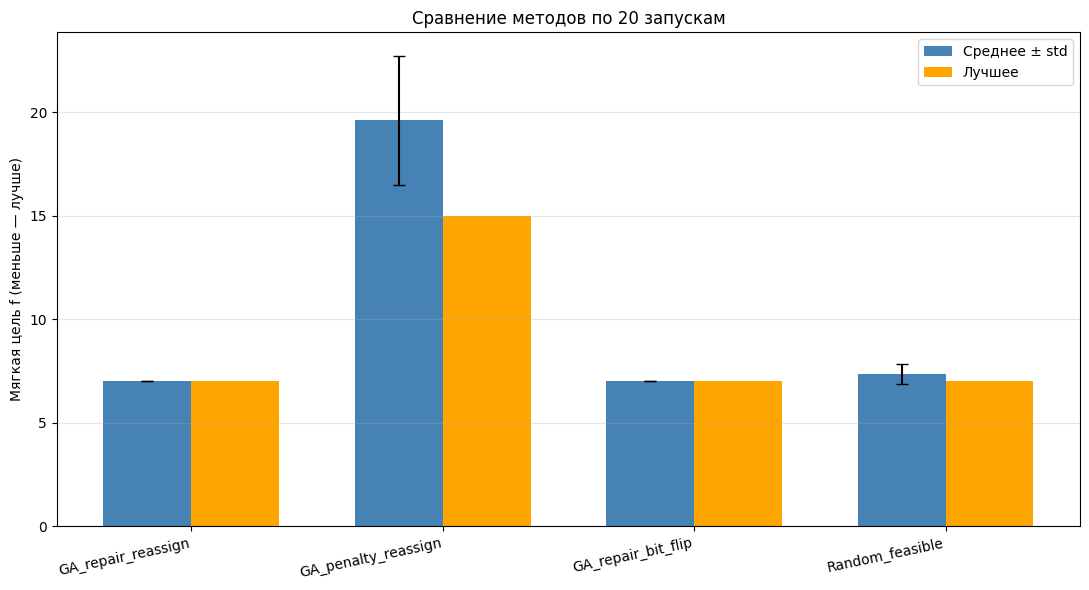

Средняя цель базового ГА: 7.000; случайного допустимого поиска: 7.350
Относительное уменьшение средней цели: 4.8%


In [5]:
for name, results in all_results.items():
    plot_convergence(results, name)

names = list(all_summaries)
means = [all_summaries[name]['mean'] for name in names]
stds = [all_summaries[name]['std'] for name in names]
bests = [all_summaries[name]['best'] for name in names]
x = np.arange(len(names))
width = 0.35
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x - width / 2, means, width, yerr=stds, capsize=4, label='Среднее ± std', color='steelblue')
ax.bar(x + width / 2, bests, width, label='Лучшее', color='orange')
ax.set_xticks(x, names, rotation=12, ha='right')
ax.set_ylabel('Мягкая цель f (меньше — лучше)')
ax.set_title('Сравнение методов по 20 запускам')
ax.grid(axis='y', alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'comparison.png', dpi=150)
plt.show()
plt.close(fig)

base_mean = all_summaries['GA_repair_reassign']['mean']
random_mean = all_summaries['Random_feasible']['mean']
print(f'Средняя цель базового ГА: {base_mean:.3f}; случайного допустимого поиска: {random_mean:.3f}')
print(f'Относительное уменьшение средней цели: {(random_mean - base_mean) / random_mean * 100:.1f}%')

## Блок-схема алгоритма

Ветвь ремонта используется в базовой конфигурации; при штрафном подходе генотип не изменяется, а нарушения добавляются к фитнесу. Элитные особи переносятся без вариации. Цикл заканчивается после точного исчерпания бюджета.

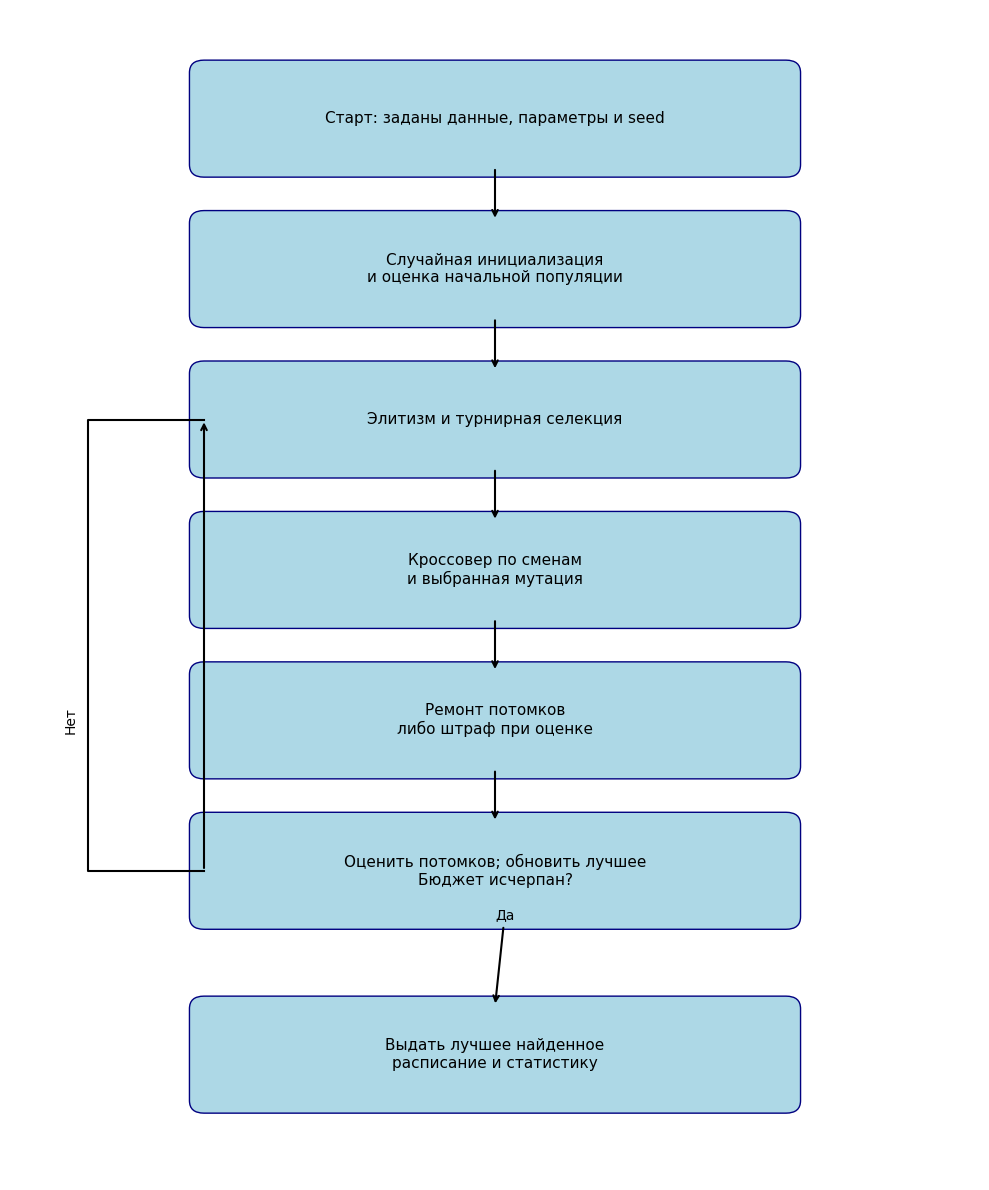

In [6]:
fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis('off')
boxes = [
    (12.7, 'Старт: заданы данные, параметры и seed'),
    (10.9, 'Случайная инициализация\nи оценка начальной популяции'),
    (9.1, 'Элитизм и турнирная селекция'),
    (7.3, 'Кроссовер по сменам\nи выбранная мутация'),
    (5.5, 'Ремонт потомков\nлибо штраф при оценке'),
    (3.7, 'Оценить потомков; обновить лучшее\nБюджет исчерпан?'),
    (1.5, 'Выдать лучшее найденное\nрасписание и статистику'),
]
for y, text in boxes:
    patch = FancyBboxPatch((2, y - 0.55), 6, 1.1, boxstyle='round,pad=0.15', facecolor='lightblue', edgecolor='navy')
    ax.add_patch(patch)
    ax.text(5, y, text, ha='center', va='center', fontsize=11)
for index in range(len(boxes) - 2):
    y = boxes[index][0]
    next_y = boxes[index + 1][0]
    ax.annotate('', xy=(5, next_y + 0.58), xytext=(5, y - 0.58), arrowprops={'arrowstyle': '->', 'lw': 1.5})
ax.annotate('Да', xy=(5, boxes[-1][0] + 0.58), xytext=(5, boxes[-2][0] - 0.58), arrowprops={'arrowstyle': '->', 'lw': 1.5})
ax.annotate('', xy=(2, 9.1), xytext=(2, 3.7), arrowprops={'arrowstyle': '->', 'lw': 1.5})
ax.plot([2, 0.8, 0.8, 2], [3.7, 3.7, 9.1, 9.1], color='black', lw=1.5)
ax.text(0.55, 5.5, 'Нет', rotation=90, va='center')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'algorithm_flowchart.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Лучшее решение и конструктивная эвристика

Лучшее допустимое решение выбирается по мягкой цели среди всех запусков всех методов. Оно сохраняется в виде бинарной матрицы и предметной таблицы. Отдельно вычисляется детерминированная по оценкам жадная эвристика; она не участвует в статистике серий. Основной равнобюджетный baseline — `Random_feasible`.

In [7]:
feasible_runs = [
    (name, result)
    for name, results in all_results.items()
    for result in results
    if result['feasible']
]
best_name, best_result = min(feasible_runs, key=lambda item: item[1]['best_objective'])
best_x = np.asarray(best_result['best_x'], dtype=np.int8)
best_metrics = solution_metrics(problem, best_x)
best_schedule = schedule_table(problem, best_x)
print(f'Лучший метод: {best_name}; seed={best_result["seed"]}; f={best_metrics["objective"]:.1f}')
print(f'Предпочтения: {best_metrics["preference"]}; дисбаланс: {best_metrics["imbalance"]:.1f}; нагрузка: {best_metrics["loads"]}')
display(best_schedule)
best_schedule.to_csv(RESULTS_DIR / 'best_schedule.csv', index_label='День недели')
save_json({'method': best_name, 'seed': best_result['seed'], 'genome': best_x.tolist(), 'metrics': best_metrics}, RESULTS_DIR / 'best_solution.json')

heuristic_rng = np.random.default_rng(problem.data_seed + 1)
heuristic_x = constructive_schedule(problem, heuristic_rng)
heuristic_metrics = solution_metrics(problem, heuristic_x)
save_json({'genome': heuristic_x.tolist(), 'metrics': heuristic_metrics}, RESULTS_DIR / 'constructive_heuristic.json')
print(f'Конструктивная эвристика: f={heuristic_metrics["objective"]:.1f}; нарушений={heuristic_metrics["hard_violations"]}')

Лучший метод: GA_repair_reassign; seed=1000; f=7.0
Предпочтения: 7; дисбаланс: 0.0; нагрузка: [3, 3, 3, 3, 3, 3, 3]


,Утро,День,Ночь
Понедельник,Сотрудник 5,Сотрудник 1,Сотрудник 3
Вторник,Сотрудник 7,Сотрудник 1,Сотрудник 2
Среда,Сотрудник 4,Сотрудник 6,Сотрудник 2
Четверг,Сотрудник 7,Сотрудник 6,Сотрудник 3
Пятница,Сотрудник 5,Сотрудник 3,Сотрудник 4
Суббота,Сотрудник 5,Сотрудник 4,Сотрудник 1
Воскресенье,Сотрудник 7,Сотрудник 2,Сотрудник 6


Конструктивная эвристика: f=11.0; нарушений=0


## Как интерпретировать результаты

Среднее и медиана показывают типичное качество, стандартное отклонение — устойчивость, а лучший результат — потенциал метода, но не заменяет серию. Различие первых двух конфигураций связано только с обработкой ограничений, различие первой и третьей — только с мутацией. Случайный допустимый поиск получает тот же бюджет, поэтому преимущество или отставание ГА нельзя объяснить большим числом оцениваний.

Численные выводы и ответ о практическом качестве решения приведены в `report.md`. Глобальная оптимальность не доказывается.